# DCGAN on CIFAR-10 with ResNet18 Evaluation

Train a convolutional GAN on CIFAR-10 and evaluate generated images using a pretrained ResNet18 classifier.

In [1]:
import os
import certifi
os.environ["SSL_CERT_FILE"] = certifi.where()

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import transforms
from torchvision.utils import make_grid
import matplotlib.pyplot as plt


In [2]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print(device)

mps


In [3]:
BATCH_SIZE=128
LATENT_DIM=100
EPOCHS=10

transform=transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))
])

dataset=torchvision.datasets.CIFAR10(root='./data',train=True,download=True,transform=transform)
loader=torch.utils.data.DataLoader(dataset,batch_size=BATCH_SIZE,shuffle=True)

100%|██████████| 170M/170M [58:54<00:00, 48.2kB/s]    


In [4]:
class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net=nn.Sequential(
            nn.ConvTranspose2d(LATENT_DIM,256,4,1,0,bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(True),
            nn.ConvTranspose2d(256,128,4,2,1,bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            nn.ConvTranspose2d(128,64,4,2,1,bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            nn.ConvTranspose2d(64,3,4,2,1,bias=False),
            nn.Tanh()
        )
    def forward(self,z):
        return self.net(z)

In [5]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net=nn.Sequential(
            nn.Conv2d(3,64,4,2,1,bias=False),
            nn.LeakyReLU(0.2,True),
            nn.Conv2d(64,128,4,2,1,bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2,True),
            nn.Conv2d(128,256,4,2,1,bias=False),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2,True),
            nn.Conv2d(256,1,4,1,0,bias=False),
            nn.Sigmoid()
        )
    def forward(self,x):
        return self.net(x).view(-1,1)

In [6]:
G=Generator().to(device)
D=Discriminator().to(device)
criterion=nn.BCELoss()
optG=optim.Adam(G.parameters(),lr=0.0002,betas=(0.5,0.999))
optD=optim.Adam(D.parameters(),lr=0.0002,betas=(0.5,0.999))

In [7]:
def show_samples(generator):
    generator.eval()
    with torch.no_grad():
        z=torch.randn(16,LATENT_DIM,1,1,device=device)
        imgs=generator(z).cpu()
    grid=make_grid(imgs,nrow=4,normalize=True)
    plt.figure(figsize=(6,6))
    plt.imshow(grid.permute(1,2,0))
    plt.axis('off')
    plt.show()
    generator.train()

1 4.217473030090332 0.4136738181114197


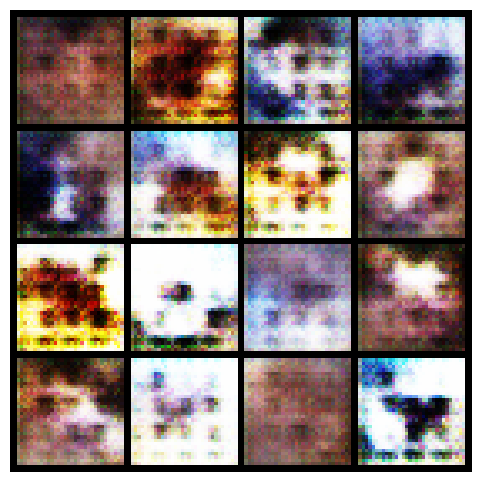

2 1.8159983158111572 0.7558329105377197


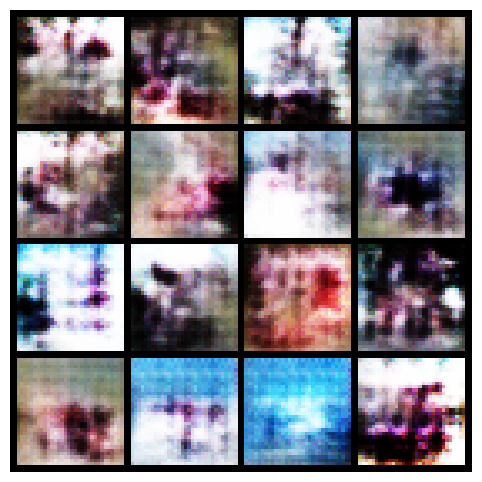

3 2.7139952182769775 0.38002246618270874


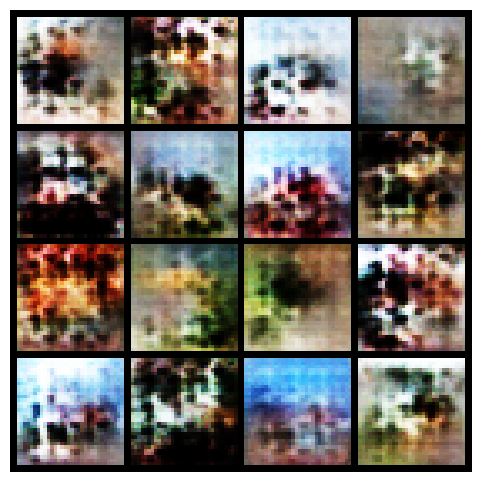

4 2.4583420753479004 0.3334723711013794


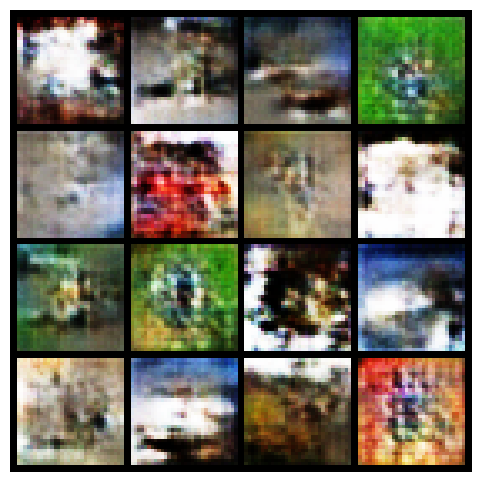

5 2.409402370452881 0.4478558897972107


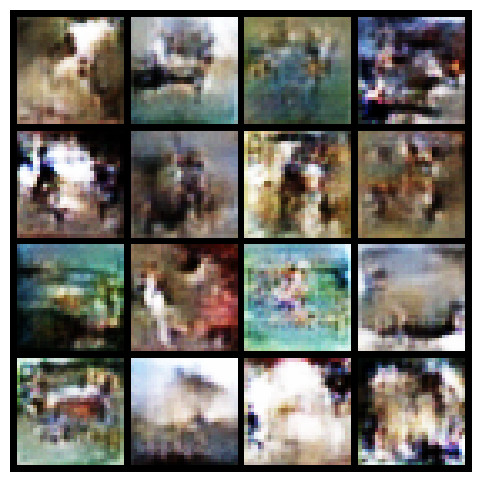

6 2.273890256881714 0.38118425011634827


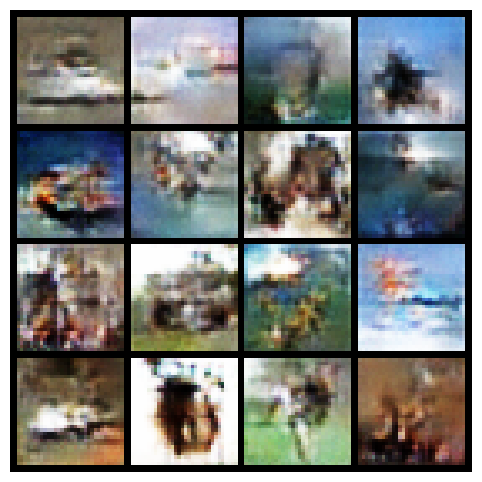

7 3.311558485031128 0.506303071975708


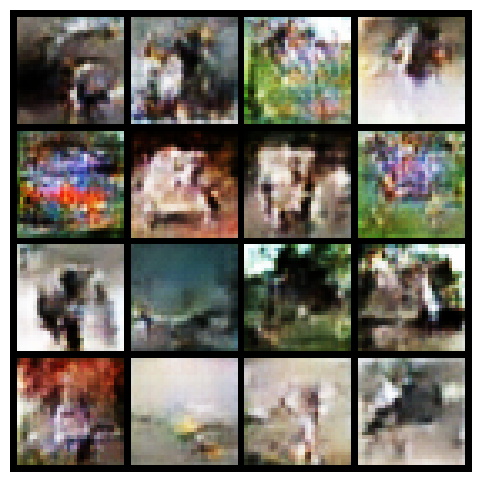

8 1.9962023496627808 0.43661966919898987


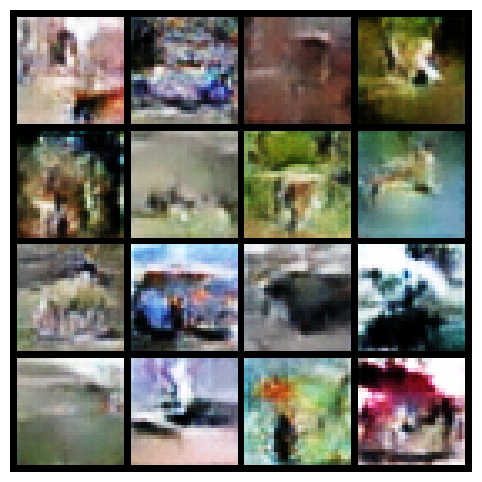

9 2.2207419872283936 0.5643649101257324


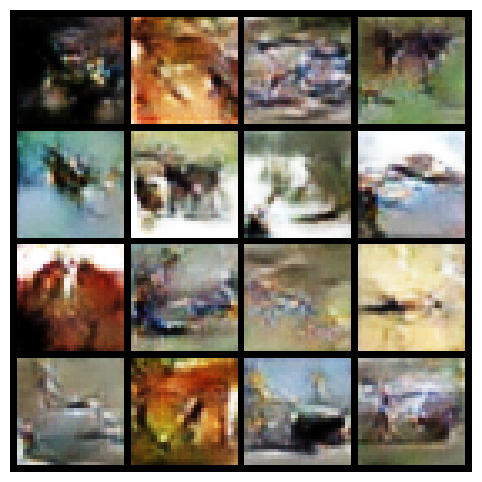

10 3.1532859802246094 0.6393934488296509


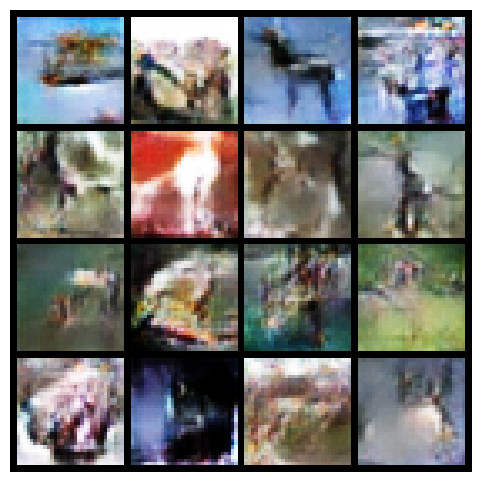

In [8]:
g_losses=[]
d_losses=[]

for epoch in range(EPOCHS):
    for real,_ in loader:
        real=real.to(device)
        b=real.size(0)

        real_y=torch.ones(b,1,device=device)
        fake_y=torch.zeros(b,1,device=device)

        noise=torch.randn(b,LATENT_DIM,1,1,device=device)
        fake=G(noise)

        d_loss=criterion(D(real),real_y)+criterion(D(fake.detach()),fake_y)
        optD.zero_grad(); d_loss.backward(); optD.step()

        noise=torch.randn(b,LATENT_DIM,1,1,device=device)
        fake=G(noise)
        g_loss=criterion(D(fake),real_y)
        optG.zero_grad(); g_loss.backward(); optG.step()

    g_losses.append(g_loss.item())
    d_losses.append(d_loss.item())
    print(epoch+1,g_loss.item(),d_loss.item())
    show_samples(G)

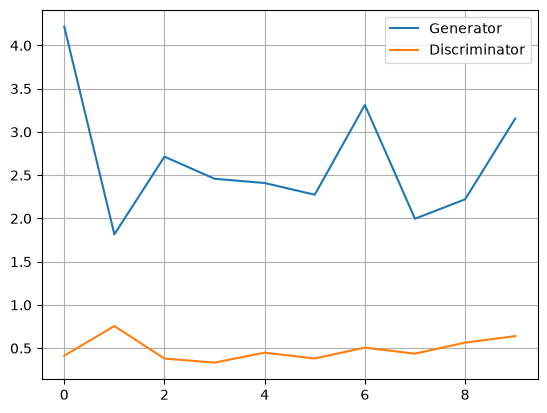

In [9]:
plt.plot(g_losses,label="Generator")
plt.plot(d_losses,label="Discriminator")
plt.legend()
plt.grid()
plt.show()

## ResNet18 Evaluation

In [10]:
from torchvision.models import resnet18, ResNet18_Weights

weights=ResNet18_Weights.DEFAULT
resnet=resnet18(weights=weights).to(device)
resnet.eval()

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/jakemasaschi/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:01<00:00, 40.5MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [11]:
eval_transform=transforms.Compose([
    transforms.Resize((224,224)),
    transforms.Normalize(mean=[0.485,0.456,0.406],std=[0.229,0.224,0.225])
])

with torch.no_grad():
    z=torch.randn(8,LATENT_DIM,1,1,device=device)
    fake=G(z).cpu()

for i in range(8):
    img=(fake[i]+1)/2
    x=eval_transform(img).unsqueeze(0).to(device)
    pred=resnet(x).softmax(dim=1)
    conf,cls=pred.max(dim=1)
    print(f'Image {i}: class={cls.item()} confidence={conf.item():.3f}')

Image 0: class=358 confidence=0.160
Image 1: class=491 confidence=0.116
Image 2: class=675 confidence=0.175
Image 3: class=335 confidence=0.089
Image 4: class=126 confidence=0.067
Image 5: class=216 confidence=0.123
Image 6: class=194 confidence=0.084
Image 7: class=675 confidence=0.881


## Student Investigation

Repeat using latent dimensions 50, 100, and 200. Compare image quality, diversity, loss curves, and ResNet18 confidence scores.